# FAQ Retrieval Comparison + RAG Demo
**Conversational AI – Semester Assignment Assistant**

This notebook uses the attached workbook `student_semester_assignment_conversational_ai_dataset.xlsx`.

| Workbook sheet | What it contains |
|---|---|
| `FAQ_Dataset` | 35 English FAQs: FAQ ID, Intent, Question, Answer |
| `Test_Queries` | 140 queries: 35 intents × 4 language styles, each with its expected FAQ ID |

**Mapping to the brief**
- *Telugu* → the workbook's **Tinglish** style (Telugu written in Latin script, mixed with English). The file has no Telugu-script text.
- *Hinglish* → Hindi written in Latin script mixed with English.
- *Finglish* (French + English) is also in the workbook. It is not in the brief, so it is reported as an extra column.
- The brief suggests ~30 test queries. The workbook has 140, and this notebook evaluates all of them. Results are more reliable with more queries.

**Pipeline:** BM25 → English embeddings (`all-MiniLM-L6-v2`) → multilingual embeddings (`multilingual-e5-small`) → Hybrid (BM25 + multilingual, RRF) → Recall@1 / Recall@3 → comparison → RAG demo with an LLM 



## 0. Initial Setup


In [23]:
%pip install -q pandas openpyxl numpy matplotlib sentence-transformers requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1–2. Load the FAQ and test-query datasets
The file path is resolved automatically from several common locations. If the file is elsewhere, set `DATA_FILE` to its full path.
In Colab, upload the file first with `from google.colab import files; files.upload()`.

In [24]:
import os, re, math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)




DATA_FILE = "student_semester_assignment_conversational_ai_dataset.xlsx"
CANDIDATE_PATHS = [
    DATA_FILE,
    os.path.join(os.getcwd(), DATA_FILE),
    f"/mnt/user-data/uploads/{DATA_FILE}",
    f"/content/{DATA_FILE}",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"{DATA_FILE} not found. Current folder: {os.getcwd()}. "
        "Put the file in this folder or set DATA_FILE to its full path."
    )
print("Using:", DATA_PATH)

faq = pd.read_excel(DATA_PATH, sheet_name="FAQ_Dataset").rename(columns={
    "FAQ ID": "faq_id", "Intent": "intent",
    "FAQ Question (English)": "question", "Answer (English)": "answer"})
tq = pd.read_excel(DATA_PATH, sheet_name="Test_Queries").rename(columns={
    "Query ID": "query_id", "Language Style": "lang",
    "Test Query": "query", "Expected FAQ ID": "expected_id"})

LANG_ORDER = ["English", "Hinglish", "Tinglish", "Finglish"]   # Tinglish = Telugu, Finglish = French (extra)
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Method names used everywhere below
M_BM25 = "BM25"
M_EN   = "English embeddings (MiniLM)"
M_ML   = "Multilingual embeddings (mE5)"
M_HY   = "Hybrid (BM25 + mE5, RRF)"

faq_pos = {fid: i for i, fid in enumerate(faq.faq_id)}
assert all(e in faq_pos for e in tq.expected_id), "Some expected FAQ IDs are missing from FAQ_Dataset"
gold = np.array([faq_pos[e] for e in tq.expected_id])

# Each FAQ is indexed as question + answer. Set to False to index only the question.
# NOTE: Srikanth's BM25 and the team agreement index the QUESTION ONLY. Set to False to match.
INDEX_ANSWERS = True
FAQ_DOCS = (faq.question + (" " + faq.answer if INDEX_ANSWERS else "")).tolist()
QUERIES = tq["query"].tolist()

print(f"FAQs: {len(faq)}   Test queries: {len(tq)}   Intents covered: {tq.expected_id.nunique()}")
print(tq.groupby("lang")["expected_id"].agg(queries="count", intents="nunique").reindex(LANG_ORDER))
faq.head()

Using: student_semester_assignment_conversational_ai_dataset.xlsx
FAQs: 35   Test queries: 140   Intents covered: 35
          queries  intents
lang                      
English        35       35
Hinglish       35       35
Tinglish       35       35
Finglish       35       35


,faq_id,intent,question,answer
0,FAQ001,View Assignments,How can I view all assignments assigned to me this semester?,Open the learning portal and use the Assignments section to view tasks across all enrolled subjects.
1,FAQ002,Subject Filter,How can I view assignments for a specific subject?,Use the subject filter in the Assignments section or open the relevant subject page.
2,FAQ003,Assignment Details,Where can I find the complete instructions for an assignment?,"Open the assignment and review its description, instructions, attachments, rubric, and lecturer notes."
3,FAQ004,Due Date,How can I check the due date of an assignment?,The due date and submission time are displayed on the assignment details page and academic calendar.
4,FAQ005,Upcoming Deadlines,How can I see assignments that are due soon?,Sort assignments by due date or use the upcoming-deadlines view on the learning portal dashboard.


## 3. BM25 retrieval (English FAQs)
BM25 is implemented from scratch, so no extra package is required. It matches exact words. On this workbook it scores lowest on **English**, because the English queries are paraphrased and avoid the FAQ wording. The Hinglish and Tinglish queries keep English keywords such as "assignment", "submit" and "deadline", so BM25 matches them more often. The overlap diagnostic below shows this. Treat the non-English BM25 scores as inflated.

In [25]:
STOPWORDS = {"a","an","the","is","are","was","to","of","in","on","for","and","or","it","be",
             "i","my","me","we","our","can","do","does","how","what","where","when","which",
             "with","from","at","this","that","there","as","by","if","so","just","any","all"}

def tokenize(text):
    return [t for t in re.findall(r"\w+", text.lower()) if t not in STOPWORDS]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.docs = [Counter(tokenize(d)) for d in docs]
        self.doc_len = np.array([sum(c.values()) for c in self.docs], dtype=float)
        self.avgdl = self.doc_len.mean()
        N = len(docs)
        df = Counter()
        for c in self.docs:
            df.update(c.keys())
        self.idf = {t: math.log(1 + (N - n + 0.5) / (n + 0.5)) for t, n in df.items()}

    def score(self, query):
        q_terms = set(tokenize(query))
        scores = np.zeros(len(self.docs))
        for i, c in enumerate(self.docs):
            s = 0.0
            for t in q_terms:
                if t in c:
                    f = c[t]
                    norm = 1 - self.b + self.b * self.doc_len[i] / self.avgdl
                    s += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * norm)
            scores[i] = s
        return scores

bm25 = BM25(FAQ_DOCS)
S_bm25 = np.vstack([bm25.score(q) for q in QUERIES])   # shape: (140 queries, 35 FAQs)

# Diagnostic: how often does BM25 find *any* keyword overlap with the FAQs?
tq["bm25_has_overlap"] = S_bm25.max(axis=1) > 0
print("Share of queries with at least one keyword match, by language:")
print(tq.groupby("lang")["bm25_has_overlap"].mean().reindex(LANG_ORDER).round(3))

Share of queries with at least one keyword match, by language:
lang
English     0.943
Hinglish    1.000
Tinglish    1.000
Finglish    1.000
Name: bm25_has_overlap, dtype: float64


## 4. English embedding retrieval (`all-MiniLM-L6-v2`)
Each FAQ and each query is encoded as a normalized vector. Because the vectors are unit length, the dot product equals cosine similarity.
This model is trained on English only. We expect it to be strongest on English and weaker on romanized Hindi and Telugu.


In [26]:
from sentence_transformers import SentenceTransformer

def dense_scores(model_name, docs, queries, doc_prefix="", query_prefix=""):
    model = SentenceTransformer(model_name)
    D = model.encode([doc_prefix + d for d in docs], normalize_embeddings=True)
    Q = model.encode([query_prefix + q for q in queries], normalize_embeddings=True)
    return model, D, Q @ D.T          # cosine similarity matrix

en_model, D_en, S_en = dense_scores("sentence-transformers/all-MiniLM-L6-v2", FAQ_DOCS, QUERIES)
print("English embedding matrix:", S_en.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

English embedding matrix: (140, 35)


## 5. Multilingual embedding retrieval (`multilingual-e5-small`)
This model handles many languages in one vector space, so it works on Hinglish and Tinglish without translation.
E5 models expect the prefixes `"query: "` and `"passage: "`. The model was trained with these prefixes, so leaving them out can lower accuracy.


In [27]:
ml_model, D_ml, S_ml = dense_scores(
    "intfloat/multilingual-e5-small", FAQ_DOCS, QUERIES,
    doc_prefix="passage: ", query_prefix="query: ")
print("Multilingual embedding matrix:", S_ml.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Multilingual embedding matrix: (140, 35)


## 6. Hybrid retrieval: BM25 + multilingual dense, fused with RRF
Reciprocal Rank Fusion ignores the raw score scales and combines the rank positions:

$$\text{RRF}(d) = \sum_{r \in \{\text{BM25}, \text{dense}\}} \frac{1}{k + \text{rank}_r(d)}, \qquad k = 60$$

A FAQ that ranks well in both lists scores highest. An FAQ with no keyword overlap gets no BM25 credit and is ranked only by the dense model.

This step needs the scores from Steps 3 and 5. It does not download anything.

In [28]:
def to_ranks(S):
    """Rank 1 = best. Scores <= 0 (no keyword overlap) share the bottom rank."""
    R = np.empty_like(S, dtype=float)
    for i, s in enumerate(S):
        order = np.argsort(-s, kind="stable")
        r = np.empty(len(s)); r[order] = np.arange(1, len(s) + 1)
        r[s <= 0] = (s > 0).sum() + 1
        R[i] = r
    return R

def rrf(score_matrices, k=60):
    fused = np.zeros_like(score_matrices[0], dtype=float)
    for S in score_matrices:
        fused += 1.0 / (k + to_ranks(S))
    return fused

S_hy = rrf([S_bm25, S_ml], k=60)

## 7. Evaluation: accuracy, precision, recall, F1 and MRR

Every query has exactly one correct FAQ, so the metrics are defined as follows (k = 1 or 3):

- **Recall@1** = share of queries where the correct FAQ is ranked first.
- **Recall@3** = share of queries where the correct FAQ appears in the top 3.


| Metric | Definition for this task | Note |
|---|---|---|
| **Accuracy** | share of queries whose correct FAQ is ranked 1st | Same as Precision@1 and Recall@1 |
| **Precision@k** | relevant FAQs in the top k ÷ k | With one relevant FAQ, equals hit@k ÷ k |
| **Recall@k** | relevant FAQs in the top k ÷ total relevant | With one relevant FAQ, equals hit@k |
| **F1@k** | 2 × P@k × R@k ÷ (P@k + R@k) | F1@1 = accuracy. F1@3 is 0.5 when the FAQ is in the top 3 |
| **MRR** | mean of 1 ÷ rank of the correct FAQ | Rewards ranking the correct FAQ higher, not just inside the top k |

Some of these values are identical by design, so this is not a bug. Accuracy, Precision@1 and Recall@1 always match, and F1@1 is the same value. Precision@3 is always one third of Recall@3. MRR is the only metric here that reflects the exact rank of the correct FAQ, so it is the most informative when two methods have the same Recall@3.

All values below are averages over queries, for each language style and overall. The table also saves the Top-1 and Top-3 retrieved FAQs for every query, as the brief asks. A method is left out of the table if its step was skipped.

In [29]:
SCORES = {M_BM25: S_bm25}
for name, S in [(M_EN, globals().get("S_en")), (M_ML, globals().get("S_ml")), (M_HY, globals().get("S_hy"))]:
    if S is not None:
        SCORES[name] = S
print("Methods evaluated:", list(SCORES))

METRIC_COLS = ["Accuracy", "Precision@1", "Recall@1", "F1@1",
               "Precision@3", "Recall@3", "F1@3", "MRR"]

def f1_score(p, r):
    denom = p + r
    return np.where(denom > 0, 2 * p * r / np.where(denom > 0, denom, 1), 0.0)

def evaluate(name, S):
    order = np.argsort(-S, axis=1, kind="stable")
    rank = (order == gold[:, None]).argmax(axis=1) + 1          # 1-based rank of the correct FAQ
    hit1 = (rank <= 1).astype(float)
    hit3 = (rank <= 3).astype(float)
    p1, r1 = hit1 / 1, hit1                                      # one relevant FAQ per query
    p3, r3 = hit3 / 3, hit3
    per_q = pd.DataFrame({
        "query_id": tq.query_id, "lang": tq.lang, "query": tq["query"],
        "expected_id": tq.expected_id,
        "expected_question": faq.question.values[gold],
        "top1_id": faq.faq_id.values[order[:, 0]],
        "top1_question": faq.question.values[order[:, 0]],
        "top3_ids": [", ".join(faq.faq_id.values[o]) for o in order[:, :3]],
        "rank_of_correct": rank,
        "Accuracy": hit1, "Precision@1": p1, "Recall@1": r1, "F1@1": f1_score(p1, r1),
        "Precision@3": p3, "Recall@3": r3, "F1@3": f1_score(p3, r3),
        "MRR": 1.0 / rank,
    })
    summ = per_q.groupby("lang")[METRIC_COLS].mean()
    summ.loc["ALL"] = per_q[METRIC_COLS].mean()
    summ = summ.reset_index().rename(columns={"lang": "Language"})
    summ.insert(0, "Method", name)
    return summ, per_q

RESULTS, SUMMARY_PARTS = {}, []
for name, S in SCORES.items():
    summ, per_q = evaluate(name, S)
    SUMMARY_PARTS.append(summ)
    RESULTS[name] = per_q
    fname = re.sub(r"\W+", "_", name).strip("_").lower()
    per_q.to_csv(f"{OUT_DIR}/top_results_{fname}.csv", index=False)

summary_df = pd.concat(SUMMARY_PARTS, ignore_index=True)
lang_cats = LANG_ORDER + ["ALL"]
summary_df["Language"] = pd.Categorical(summary_df["Language"], categories=lang_cats, ordered=True)
summary_df = summary_df.sort_values(["Method", "Language"]).reset_index(drop=True)
summary_df.to_csv(f"{OUT_DIR}/retrieval_metrics_summary.csv", index=False)

print("Per-query Top-1 / Top-3 results saved to ./outputs/ (one CSV per method)")
display_df = summary_df.copy()
for c in METRIC_COLS:
    display_df[c] = display_df[c].map("{:.1%}".format if c != "MRR" else "{:.3f}".format)
display_df

Methods evaluated: ['BM25', 'English embeddings (MiniLM)', 'Multilingual embeddings (mE5)', 'Hybrid (BM25 + mE5, RRF)']
Per-query Top-1 / Top-3 results saved to ./outputs/ (one CSV per method)


,Method,Language,Accuracy,Precision@1,Recall@1,F1@1,Precision@3,Recall@3,F1@3,MRR
0,BM25,English,37.1%,37.1%,37.1%,37.1%,18.1%,54.3%,27.1%,0.493
1,BM25,Hinglish,82.9%,82.9%,82.9%,82.9%,30.5%,91.4%,45.7%,0.888
2,BM25,Tinglish,80.0%,80.0%,80.0%,80.0%,30.5%,91.4%,45.7%,0.874
3,BM25,Finglish,91.4%,91.4%,91.4%,91.4%,33.3%,100.0%,50.0%,0.952
4,BM25,ALL,72.9%,72.9%,72.9%,72.9%,28.1%,84.3%,42.1%,0.802
5,English embeddings (MiniLM),English,71.4%,71.4%,71.4%,71.4%,31.4%,94.3%,47.1%,0.819
6,English embeddings (MiniLM),Hinglish,82.9%,82.9%,82.9%,82.9%,30.5%,91.4%,45.7%,0.883
7,English embeddings (MiniLM),Tinglish,82.9%,82.9%,82.9%,82.9%,31.4%,94.3%,47.1%,0.895
8,English embeddings (MiniLM),Finglish,88.6%,88.6%,88.6%,88.6%,32.4%,97.1%,48.6%,0.934
9,English embeddings (MiniLM),ALL,81.4%,81.4%,81.4%,81.4%,31.4%,94.3%,47.1%,0.883


## 8. Compare and analyze the methods
The Hinglish, Tinglish and Finglish scores for lexical methods are inflated

                              Recall@1                                   Recall@3                                  
Language                       English Hinglish Tinglish Finglish    ALL  English Hinglish Tinglish Finglish    ALL
Method                                                                                                             
BM25                             0.371    0.829    0.800    0.914  0.729    0.543    0.914    0.914    1.000  0.843
English embeddings (MiniLM)      0.714    0.829    0.829    0.886  0.814    0.943    0.914    0.943    0.971  0.943
Hybrid (BM25 + mE5, RRF)         0.600    0.943    0.943    1.000  0.871    0.771    1.000    1.000    1.000  0.943
Multilingual embeddings (mE5)    0.686    0.857    0.886    0.943  0.843    0.800    1.000    0.971    1.000  0.943


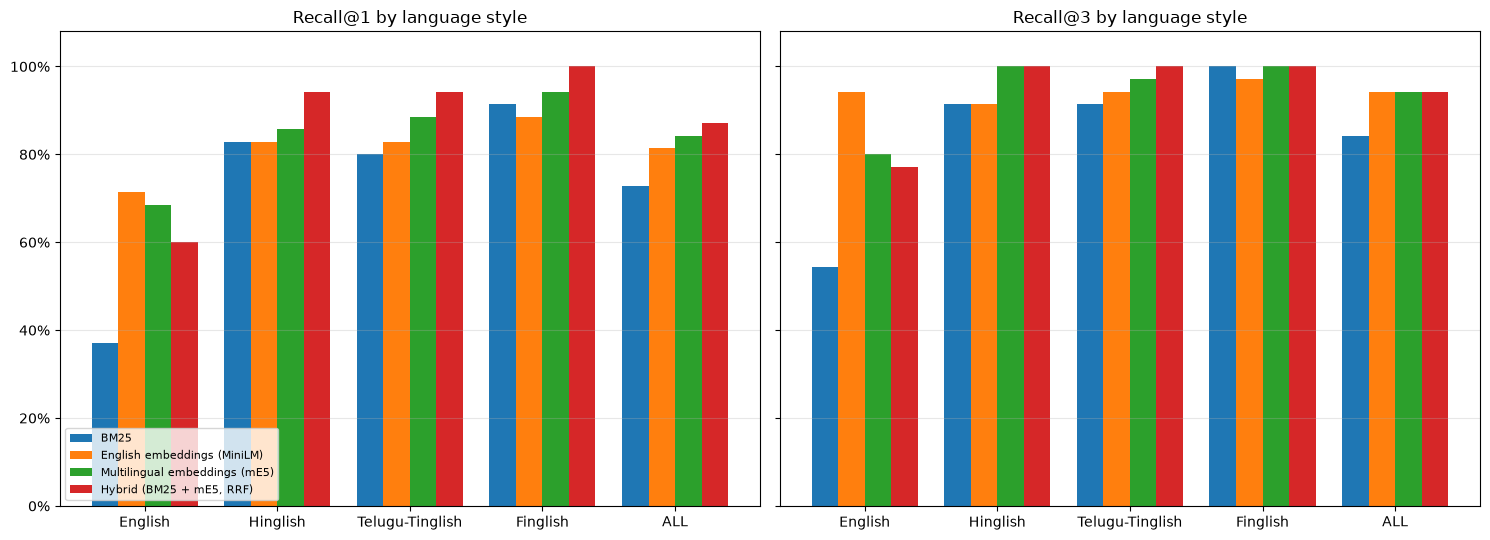


Best overall retriever: Hybrid (BM25 + mE5, RRF)  (Recall@1 = 87.1%, Recall@3 = 94.3%)
  Best for English  : English embeddings (MiniLM) (Recall@1 = 71.4%)
  Best for Hinglish : Hybrid (BM25 + mE5, RRF) (Recall@1 = 94.3%)
  Best for Tinglish : Hybrid (BM25 + mE5, RRF) (Recall@1 = 94.3%)
  Best for Finglish : Hybrid (BM25 + mE5, RRF) (Recall@1 = 100.0%)


In [30]:
# Comparison table
pivot = summary_df.pivot(index="Method", columns="Language", values=["Recall@1", "Recall@3"])
print(pivot.round(3).to_string())

# Chart
langs = lang_cats
methods = list(SCORES.keys())
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
width = 0.8 / len(methods)
x = np.arange(len(langs))
for ax, metric in zip(axes, ["Recall@1", "Recall@3"]):
    for j, m in enumerate(methods):
        vals = [summary_df[(summary_df.Method == m) & (summary_df.Language == l)][metric].item() for l in langs]
        ax.bar(x + (j - (len(methods) - 1) / 2) * width, vals, width, label=m)
    ax.set_xticks(x)
    ax.set_xticklabels(["Telugu-Tinglish" if l == "Tinglish" else l for l in langs])
    ax.set_title(f"{metric} by language style")
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/retriever_comparison.png", dpi=150)
plt.show()

# Best retriever
overall = summary_df[summary_df.Language == "ALL"].sort_values(["Recall@1", "Recall@3"], ascending=False)
BEST_METHOD = overall.iloc[0]["Method"]
print(f"\nBest overall retriever: {BEST_METHOD}  "
      f"(Recall@1 = {overall.iloc[0]['Recall@1']:.1%}, Recall@3 = {overall.iloc[0]['Recall@3']:.1%})")
for lang in LANG_ORDER:
    sub = summary_df[summary_df.Language == lang].sort_values("Recall@1", ascending=False).iloc[0]
    print(f"  Best for {lang:<9}: {sub['Method']} (Recall@1 = {sub['Recall@1']:.1%})")

## 9. Failure
The examples below comes from the best retriever.A query with no keyword overlap cannot be solved by BM25 alone.

In [31]:
best_q = RESULTS[BEST_METHOD]
misses = best_q[best_q.rank_of_correct > 1]   # correct FAQ not ranked first
print(f"{BEST_METHOD}: {len(misses)} Top-1 misses out of {len(best_q)} queries")
print(misses.groupby("lang").size().reindex(LANG_ORDER).fillna(0).astype(int).to_string())
print()
cols = ["query_id", "lang", "query", "expected_question", "top1_question", "rank_of_correct"]
print(misses.groupby("lang").head(3)[cols].to_string(index=False))

Hybrid (BM25 + mE5, RRF): 18 Top-1 misses out of 140 queries
lang
English     14
Hinglish     2
Tinglish     2
Finglish     0

query_id     lang                                                                   query                                                         expected_question                                                          top1_question  rank_of_correct
   TQ001  English              Where can I get a complete list of my semester coursework?              How can I view all assignments assigned to me this semester?          Where can I find the complete instructions for an assignment?                2
   TQ005  English       I only want to see the tasks for one class. How do I filter them?                        How can I view assignments for a specific subject?               How can I see assignments that I have already completed?                2
   TQ017  English                     Which pieces of coursework need my attention first?                            

## 10. RAG demo
The pipeline is:
1. The user asks a question.
2. The best retriever finds the most relevant English FAQ.
3. The retrieved FAQ is passed to an LLM with instructions to answer only from that FAQ.
4. The LLM writes the final answer.

The LLM runs locally through **Ollama** (no API key needed). If Ollama is not running, the demo falls back to returning the retrieved FAQ answer directly, so the retrieval step can still be tested.

In [32]:
MODEL_LOOKUP = {M_EN: (en_model, D_en, ""), M_ML: (ml_model, D_ml, "query: ")}

def retrieval_scores(question, method):
    """Score all 35 FAQs for one new question, using the chosen retriever."""
    if method == M_BM25:
        return bm25.score(question)
    if method in MODEL_LOOKUP:
        model, D, prefix = MODEL_LOOKUP[method]
        q = model.encode([prefix + question], normalize_embeddings=True)[0]
        return D @ q
    if method == M_HY:
        return rrf([bm25.score(question)[None, :],
                    retrieval_scores(question, M_ML)[None, :]])[0]
    raise ValueError(f"Unknown method: {method}")

import requests

OLLAMA_MODEL = "llama3.2:3b"   # must match a name shown by `ollama list`
OLLAMA_URL = "http://localhost:11434/api/generate"

def generate_answer(question, faq_row):
    prompt = (
        "You are a semester assignment assistant for students.\n"
        "A retrieval system matched the student's question to the FAQ below. "
        "The question may be in English, Hinglish, romanized Telugu, or French mixed with English; "
        "understand it, but always reply in English.\n"
        "Answer using ONLY the FAQ answer, rephrased in 2-3 sentences. "
        "Do not add any steps or facts that are not in the FAQ answer.\n"
        "If the FAQ question is about a different topic than the student's question, "
        "reply exactly: I could not find a matching FAQ for this question. Please contact the course office.\n\n"
        f"FAQ question: {faq_row.question}\n"
        f"FAQ answer: {faq_row.answer}\n\n"
        f"Student question: {question}"
    )
    try:
        r = requests.post(
            OLLAMA_URL,
            json={"model": OLLAMA_MODEL, "prompt": prompt, "stream": False,
                  "options": {"temperature": 0}},
            timeout=120,
        )
        r.raise_for_status()
        return r.json()["response"].strip()
    except requests.exceptions.RequestException as e:
        # Ollama not running or model not pulled: fall back to the FAQ answer
        print(f"[Ollama unavailable: {type(e).__name__}] returning the FAQ answer directly")
        return faq_row.answer

def rag_answer(question, method=None):
    method = method or BEST_METHOD
    scores = retrieval_scores(question, method)
    row = faq.iloc[int(np.argmax(scores))]
    return {
        "question": question,
        "retriever": method,
        "retrieved_id": row.faq_id,
        "retrieved_faq": row.question,
        "answer": generate_answer(question, row),
    }

In [33]:
# Demo on a few questions from each language style (one per language)
demo_rows = tq.groupby("lang").head(2).head(8)
for _, r in demo_rows.iterrows():
    out = rag_answer(r["query"])
    print(f"[{r.lang}] {r['query']}")
    print(f"   Retrieved : {out['retrieved_id']} – {out['retrieved_faq']}"
          f"  {'✓' if out['retrieved_id'] == r.expected_id else '✗ expected ' + r.expected_id}")
    print(f"   Answer    : {out['answer']}\n")

# Try your own question
custom = rag_answer("Can I upload more than one file for a single assignment?")
print(custom)

[English] Where can I get a complete list of my semester coursework?
   Retrieved : FAQ003 – Where can I find the complete instructions for an assignment?  ✗ expected FAQ001
   Answer    : I could not find a matching FAQ for this question. Please contact the course office.

[Hinglish] Mere semester ke saare assignments ek jagah kaise dekh sakta hoon?
   Retrieved : FAQ001 – How can I view all assignments assigned to me this semester?  ✓
   Answer    : To view all assignments assigned to you this semester, open the learning portal and use the Assignments section to view tasks across all enrolled subjects. This will allow you to see all your assignments in one place. You can access the Assignments section from the learning portal.

[Tinglish] Na semester lo unna anni assignments okate place lo ela chudali?
   Retrieved : FAQ001 – How can I view all assignments assigned to me this semester?  ✓
   Answer    : You can view all assignments assigned to you this semester by opening the learnin